# LSTM

Model implementation intentionally omitted from the public repository.


Epoch 01/40 | Train Loss: 0.000076 (109.428s) | Val Loss: 0.000061 (8.160s)
Epoch 02/40 | Train Loss: 0.000053 (104.264s) | Val Loss: 0.000048 (8.228s)
Epoch 03/40 | Train Loss: 0.000048 (108.724s) | Val Loss: 0.000045 (9.831s)
Epoch 04/40 | Train Loss: 0.000045 (26.211s) | Val Loss: 0.000044 (1.438s)
Epoch 05/40 | Train Loss: 0.000043 (9.981s) | Val Loss: 0.000043 (1.331s)
Epoch 06/40 | Train Loss: 0.000042 (9.953s) | Val Loss: 0.000044 (1.270s)
Epoch 07/40 | Train Loss: 0.000041 (10.163s) | Val Loss: 0.000040 (1.396s)
Epoch 08/40 | Train Loss: 0.000041 (10.755s) | Val Loss: 0.000041 (1.383s)
Epoch 09/40 | Train Loss: 0.000040 (10.280s) | Val Loss: 0.000042 (1.370s)
Epoch 10/40 | Train Loss: 0.000040 (9.650s) | Val Loss: 0.000042 (1.254s)
Epoch 11/40 | Train Loss: 0.000040 (9.748s) | Val Loss: 0.000040 (1.246s)
Epoch 12/40 | Train Loss: 0.000039 (9.727s) | Val Loss: 0.000039 (1.452s)
Epoch 13/40 | Train Loss: 0.000039 (11.332s) | Val Loss: 0.000039 (1.419s)
Epoch 14/40 | Train Loss: 0

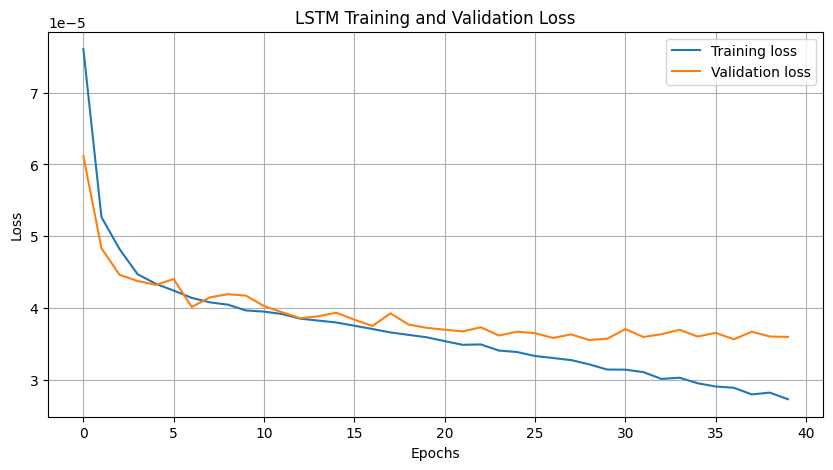

In [12]:
lstm_model.run_model((train_x,train_y), (test_x, test_y))

=== 1. Benchmarking Sequence Preprocessing: CPU vs Unaccelerated GPU vs Custom CUDA Kernel ===


shapes 15 15 torch.Size([118, 10, 10]) torch.Size([118])
[Preprocessing Benchmark] CPU: 1712.7 ms | Unaccelerated GPU: 67.7 ms | Custom CUDA: 35.2 ms
Total Preprocessing Time (15 tracks):
  CPU (.iloc loop): 1712.72 ms
  Unaccelerated GPU: 67.66 ms
  Custom CUDA Kernel: 35.23 ms
  CPU / Unaccelerated GPU: 25.3x
  CPU / Custom CUDA Kernel: 48.6x
Train shape: torch.Size([2574, 10, 10]), Test shape: torch.Size([859, 10, 10])

=== 2. Training LSTM Model with Per-Epoch Latency Profiling ===
Epoch 01/15 | Train Loss: 0.000630 (0.341s) | Val Loss: 0.000403 (0.049s)
Epoch 02/15 | Train Loss: 0.000379 (0.181s) | Val Loss: 0.000326 (0.014s)
Epoch 03/15 | Train Loss: 0.000305 (0.118s) | Val Loss: 0.000265 (0.013s)
Epoch 04/15 | Train Loss: 0.000252 (0.173s) | Val Loss: 0.000233 (0.032s)
Epoch 05/15 | Train Loss: 0.000223 (0.446s) | Val Loss: 0.000194 (0.077s)
Epoch 06/15 | Train Loss: 0.000201 (0.249s) | Val Loss: 0.000172 (0.034s)
Epoch 07/15 | Train Loss: 0.000179 (0.220s) | Val Loss: 0.000172 

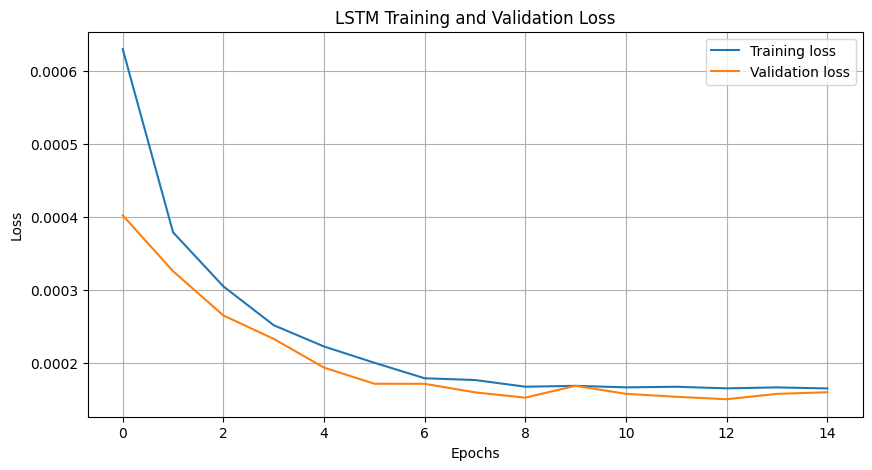


=== 3. Rendering Acceleration & Performance Dashboard ===


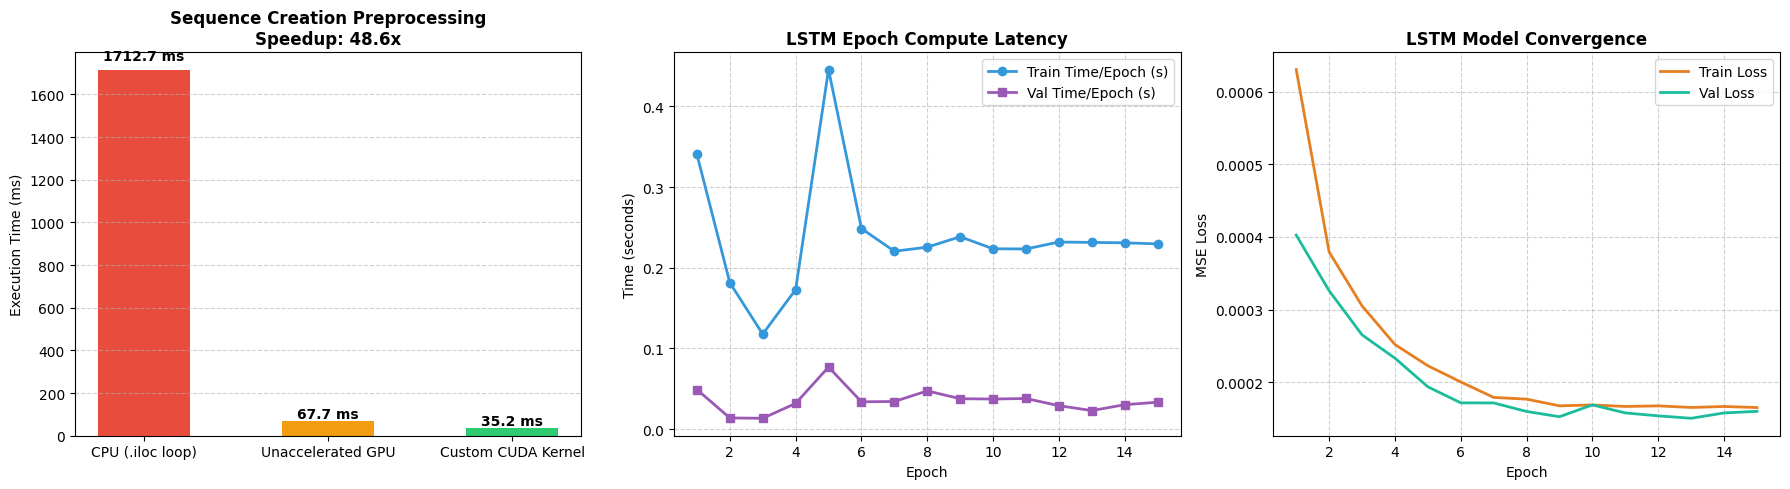

In [13]:
## CUDA vs CPU Benchmark, Model Training & Latency Dashboard
print("=== 1. Benchmarking Sequence Preprocessing: CPU vs Unaccelerated GPU vs Custom CUDA Kernel ===")
sample_ids = all_columns_present_id_list[:15]  # Benchmark on 15 tracks
X_bench, y_bench, _, cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms = read_data(sample_ids, normalised=True, benchmark=True)
cuda_benchmark_available = bool(torch.cuda.is_available() and cuda_prep_ms > 0.0)

print(f"Total Preprocessing Time (15 tracks):")
print(f"  CPU (.iloc loop): {cpu_prep_ms:.2f} ms")
if cuda_benchmark_available:
    print(f"  Unaccelerated GPU: {gpu_unaccelerated_prep_ms:.2f} ms")
    print(f"  Custom CUDA Kernel: {cuda_prep_ms:.2f} ms")
    print(f"  CPU / Unaccelerated GPU: {cpu_prep_ms / max(gpu_unaccelerated_prep_ms, 1e-4):.1f}x")
    print(f"  CPU / Custom CUDA Kernel: {cpu_prep_ms / max(cuda_prep_ms, 1e-4):.1f}x")
else:
    print("  Unaccelerated GPU: unavailable")
    print("  Custom CUDA Kernel: unavailable (CPU fallback used)")

# Split sequences
(train_x, train_y), (test_x, test_y) = divide_sequences(X_bench, y_bench)
print(f"Train shape: {train_x.shape}, Test shape: {test_x.shape}")

print("\n=== 2. Training LSTM Model with Per-Epoch Latency Profiling ===")
lstm_model_timed = LSTMModel(input_size=train_x.shape[2], hidden_size=64, num_layers=2, lr=0.001, batch_size=64)
lstm_model_timed.run_model((train_x, train_y), (test_x, test_y), epochs=15)

print("\n=== 3. Rendering Acceleration & Performance Dashboard ===")
if cuda_benchmark_available:
    plot_cuda_comparison_dashboard(cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms, lstm_model_timed, model_name="LSTM")
else:
    print("CUDA comparison dashboard skipped because the custom CUDA benchmark did not run.")


In [14]:
cuda_benchmark_available = _CUDA_AVAILABLE and torch.cuda.is_available()
print(cuda_benchmark_available)

True
